# HTML vs PDF: what each format destroys, measured

The research behind [docs/PARSING.md](../docs/PARSING.md). Every number in that
document should be traceable to a cell here.

**The question.** Our corpus holds two formats for the same companies and years —
SEC 10-K filings as HTML, and the glossy Annual Report to Shareholders (form ARS) as
PDF. What does each format hand you, what does it destroy, and what does it cost to
recover?

**Why this matters before Phase 2.** Parsing is where most RAG quality is won or
lost, and the parser you pick is only defensible if you measured the alternatives on
*your* documents.

**Measurement logic lives in [`rag/ingest/format_probe.py`](../rag/ingest/format_probe.py)**,
not in these cells — so it can be tested, reused by the pipeline, and re-run when the
corpus changes. The notebook calls it and shows the result.

In [1]:
import json, os, re, sys
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

from rag.ingest.format_probe import (
    html_probe, pdf_probe, table_recovery, cached,
    strip_naive, strip_inline_aware, AMOUNT,
)

INK, INK2, SURF = "#0b0b0b", "#52514e", "#fcfcfb"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"     # validated categorical slots 1-3
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "text.color": INK,
    "axes.labelcolor": INK2, "axes.edgecolor": "#d8d7d2",
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#eceae4", "grid.linewidth": 0.8,
})

metas = [json.loads(l) for l in open("data/raw/manifest.jsonl")]
html_docs = [m for m in metas if m["path"].endswith(".htm")]
pdf_docs  = [m for m in metas if m["path"].endswith(".pdf")]
print(f"corpus: {len(html_docs)} HTML + {len(pdf_docs)} PDF = {len(metas)} documents")

corpus: 65 HTML + 55 PDF = 120 documents


## 0. Integrity first

Every measurement below reads files from disk. If disk and manifest disagree, every
number is wrong while the manifest still looks authoritative.

This check exists because a real corruption slipped through: one 10-K was 19,075,544
bytes on disk against 12,927,325 recorded — found only because a derived ratio came
out wrong (7.9% vs 11.7%) and the discrepancy was chased. The manifest had stored a
sha256 for every file since the first fetch, and nothing had ever checked it.

In [2]:
!python -m rag.cli corpus verify


120 documents in manifest
  verified            120
  missing on disk       0
  size mismatch         0
  checksum mismatch     0

all documents match the manifest.



## 1. HTML: the structure is there, but not the structure you want

A 10-K is inline-XBRL: XHTML with every reported figure wrapped in a semantic tag.

In [3]:
JPM = "data/raw/edgar_jpmorgan_FY2025_10k_008131.htm"
h = html_probe(JPM)
pd.Series({
    "raw chars":            f"{h['raw_chars']:,}",
    "text chars":           f"{h['text_chars']:,}",
    "text ratio":           f"{h['text_ratio']:.1%}",
    "<table> elements":     f"{h['tables']:,}",
    "<td> paired":          f"{h['td_paired']:,}",
    "<td/> self-closing":   f"{h['td_self_closing']:,}",
    "inline XBRL tags":     f"{h['xbrl_tags']:,}",
}, name="JPMorgan FY2025 10-K").to_frame()

,JPMorgan FY2025 10-K
raw chars,"12,927,325"
text chars,"1,513,182"
text ratio,11.7%
<table> elements,679
<td> paired,"22,610"
<td/> self-closing,"37,738"
inline XBRL tags,"8,738"


Two things stand out.

**Only ~12% of the bytes are text.** The rest is markup — largely inline XBRL, which
is a *gift*: it names each figure's concept, unit and scale.

**Self-closing `<td/>` spacers outnumber real cells.** 37,738 against 22,610 paired
cells — roughly **62% of all cells exist purely for print spacing**. A naive
row-reader sees mostly blanks.

Here is what an XBRL-tagged figure looks like:

In [4]:
raw = Path(JPM).read_text(encoding="utf-8", errors="ignore")
i = raw.find("EntityPublicFloat")
print(re.sub(r"\s+", " ", raw[i-120:i+180]))

eld by non-affiliates as of June&#160;30, 2025: $<ix:nonFraction unitRef="usd" contextRef="c-12" decimals="0" name="dei:EntityPublicFloat" format="ixt:num-dot-decimal" scale="0" id="f-54">794,433,813,496</ix:nonFraction></span></div><div style="margin-bottom:6pt;margin-top:3pt;text-align:center"><sp


`dei:EntityPublicFloat` tells you exactly what that number *means*, with its unit
and scale. Almost nobody uses it — arguably the most under-exploited signal in
financial RAG.

## 2. Where did the dollar signs go?

A simple question: **how many dollar amounts are in this filing?** It took three
attempts to answer, and the failures matter more than the answer.

In [5]:
# ATTEMPT 1 — strip tags, match '$' followed by digits/commas.
naive = strip_naive(raw)
a1 = len(re.findall(r"\$[\d,]+", naive))
print(f"attempt 1:  {a1} dollar amounts")
print(f"            but the file contains {raw.count('$'):,} '$' characters")

attempt 1:  328 dollar amounts
            but the file contains 3,725 '$' characters


**Attempt 1 was caught only because the answer had to be non-zero** — a bank's
annual report obviously contains dollar amounts. The count was implausible, so it got
questioned.

In [6]:
# ATTEMPT 2 — require at least 4 digit/comma chars, to skip page numbers.
a2_attached = len(re.findall(r"\$[\d,]{4,}", naive))
a2_split    = len(re.findall(r"\$\s+[\d,]{4,}", naive))
print(f"attempt 2:  attached {a2_attached}, split {a2_split}"
      f"  ->  {a2_split/(a2_attached+a2_split):.0%} 'split'")
print()
print("Why it is wrong — the quantifier cannot match a decimal point:")
for s in ["$4.4 trillion", "$362.4 billion", "$794,433,813,496"]:
    print(f"   {s:22} {'MATCH' if re.match(r'\$[\d,]{4,}', s) else 'MISSED'}")

attempt 2:  attached 2, split 2042  ->  100% 'split'

Why it is wrong — the quantifier cannot match a decimal point:
   $4.4 trillion          MISSED
   $362.4 billion         MISSED
   $794,433,813,496       MATCH


**Attempt 2 survived longer than attempt 1 because its answer looked plausible.**
`[\d,]{4,}` silently excludes every amount containing a decimal point, and the regex
then matched a *later* number instead, inflating the "split" count.

The defence: predict the answer's rough magnitude before measuring, and verify a
headline number by a structurally different method.

In [7]:
# ATTEMPT 3 — an amount pattern that admits decimals, plus two extraction strategies.
rows = []
for label, text in (("naive: every tag -> ' '", strip_naive(raw)),
                    ("inline-aware: inline tag -> ''", strip_inline_aware(raw))):
    att = len(re.findall(rf"\${AMOUNT}", text))
    spl = len(re.findall(rf"\$\s+{AMOUNT}", text))
    rows.append({"strategy": label, "attached": att, "split": spl,
                 "attached %": f"{att/(att+spl):.0%}"})
pd.DataFrame(rows).set_index("strategy")

,attached,split,attached %
strategy,,,
naive: every tag -> ' ',328,3004,10%
inline-aware: inline tag -> '',780,2552,23%


Inline-tag awareness roughly doubles recovery (10% -> 23%) and still leaves 77% broken. So the
separator is not a tag — it is something structural. Check the cells directly:

In [8]:
pd.Series({
    "cells containing ONLY '$'":            f"{h['dollar_only_cells']:,}",
    "of those, next cell is a number":      f"{h['dollar_cell_then_number']:,}",
    "cells containing only a number":       f"{h['number_only_cells']:,}",
}, name="count").to_frame()

,count
cells containing ONLY '$',"2,922"
"of those, next cell is a number","2,552"
cells containing only a number,"10,579"


**The currency symbol occupies its own table cell.** 2,922 cells hold nothing but
`$`, and 87% of them are immediately followed by a cell holding nothing but a number.

That count matches the unrecovered "split" figure above — so the mechanism is
confirmed, not inferred.

> ### The conclusion that drives Phase 2
> **This is not fixable by text processing.** No regex, no whitespace rule, no tag
> heuristic can reunite `$` with its value across a table-cell boundary. The only
> correct fix is to parse the table **as a grid** and reassemble each value from its
> cell group.
>
> And the same applies to the thing that actually matters: when the row header,
> column header and value are all in separate cells and get flattened into one line,
> the *binding* between label and number is destroyed — and that binding **is** the
> answer.

## 3. PDF: nothing is declared

A PDF stores positioned glyphs, not structure.

In [9]:
import pymupdf
d = pymupdf.open("data/raw/edgar_jpmorgan_FY2025_ars_023927.pdf")
for w in d[4].get_text("words")[:6]:
    print(f"   x0={w[0]:7.1f}  y0={w[1]:7.1f}   {w[4]!r}")

   x0=  153.6  y0=   70.4   'by'
   x0=  167.6  y0=   70.4   'large'
   x0=  194.0  y0=   70.4   'amounts'
   x0=  238.2  y0=   70.4   'of'
   x0=  249.8  y0=   70.4   'government'
   x0=  310.1  y0=   70.4   'deficit'


No rows, no cells, no columns, no reading order. To know that two words on the
same line belong to different columns, you have to infer it from geometry.

Measured across our annual-report PDFs:

In [10]:
SAMPLE = ["jpmorgan", "bofa", "citigroup", "goldman", "citizens", "morganstanley"]
rows = []
for slug in SAMPLE:
    f = next(m["path"] for m in pdf_docs if f"_{slug}_" in m["path"] and "FY2024" in m["path"])
    p = pdf_probe(f, table_sample=12)
    rows.append({"company": slug, "pages": p["pages"], "empty pages": p["empty_pages"],
                 "tokens": p["est_tokens"], "ligatures": p["ligatures"],
                 "hyphen breaks": p["hyphen_breaks"], "images(1-40)": p["images_first40"]})
pd.DataFrame(rows).set_index("company")

Consider using the pymupdf_layout package for a greatly improved page layout analysis.


,pages,empty pages,tokens,ligatures,hyphen breaks,images(1-40)
company,,,,,,
jpmorgan,372,0,337823,0,959,2
bofa,224,0,231527,3,92,42
citigroup,346,2,326403,0,203,37
goldman,267,2,251365,0,1,11
citizens,194,167,13074,0,11,116
morganstanley,175,0,212936,86,2,27


**Citizens FY2024 is the outlier that matters** — see section 5.

## 4. The headline: scoring PDF extraction against the HTML

Because we hold both formats for the same company-year, the HTML's declared
`<table>` count is **ground truth**. That makes a parser bake-off scoreable without
hand-labelling a single page.

This scan takes several minutes, so it is cached to `data/interim/`. Delete that file
to force a recompute.

In [11]:
def build_pairs():
    out = []
    for pm in pdf_docs:
        stem = Path(pm["path"]).stem              # edgar_<slug>_FY20xx_ars_<tail>
        parts = stem.split("_"); slug, fy = parts[1], parts[2]
        hm = [m for m in html_docs if f"_{slug}_{fy}_10k" in m["path"]]
        if not hm:
            continue
        hp = html_probe(hm[0]["path"])
        pp = pdf_probe(pm["path"], table_sample=25)
        out.append({"slug": slug, "fy": fy,
                    "html_tokens": hm[0]["est_tokens"], "pdf_tokens": pp["est_tokens"],
                    "html_tables": hp["tables"], "pdf_tables": pp["tables_estimated"],
                    "pages": pp["pages"], "empty_pages": pp["empty_pages"],
                    "recovery": table_recovery(hp, pp)})
    return out

pairs = pd.DataFrame(cached("data/interim/pair_recovery.json", build_pairs))
print(f"{len(pairs)} HTML/PDF pairs")
pairs.recovery.describe()[["min", "25%", "50%", "75%", "max"]].to_frame("table recovery")

55 HTML/PDF pairs


,table recovery
min,0.000000
25%,0.043261
50%,0.143646
75%,0.267138
max,0.854167


In [12]:
by_co = (pairs.groupby("slug")
              .agg(recovery=("recovery", "mean"), html_tables=("html_tables", "mean"),
                   pdf_tables=("pdf_tables", "mean"), n=("recovery", "size"))
              .sort_values("recovery", ascending=False))
by_co.style.format({"recovery": "{:.1%}", "html_tables": "{:.0f}", "pdf_tables": "{:.0f}"})

,recovery,html_tables,pdf_tables,n
slug,,,,
truist,62.3%,146,90,4
citigroup,54.0%,338,182,4
jpmorgan,47.8%,668,317,4
schwab,27.3%,127,34,4
capitalone,20.7%,471,101,4
bofa,16.9%,367,62,4
usbancorp,15.3%,374,53,4
statestreet,13.7%,214,29,4
citizens,11.8%,310,36,3


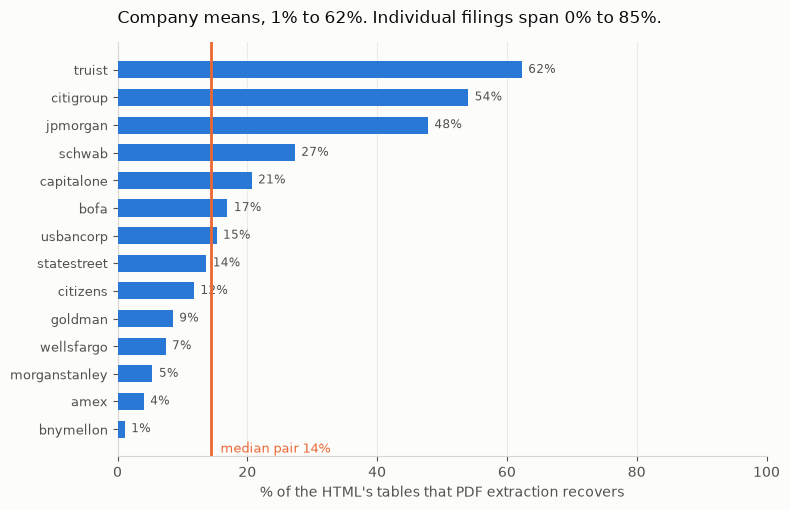

In [13]:
fig, ax = plt.subplots(figsize=(8, 5.2))
y = range(len(by_co))
ax.barh(list(y), by_co.recovery * 100, height=0.62, color=C1, zorder=3)
med = pairs.recovery.median() * 100
ax.axvline(med, color=C2, lw=2, zorder=4)
ax.text(med + 1.5, len(by_co) - 0.15, f"median pair {med:.0f}%", color=C2, fontsize=9)
for i, v in enumerate(by_co.recovery * 100):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(list(y)); ax.set_yticklabels(by_co.index, fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("% of the HTML's tables that PDF extraction recovers")
ax.set_title("Company means, 1% to 62%. Individual filings span 0% to 85%.",
             fontsize=12, color=INK, pad=14, loc="left")
ax.grid(True, axis="x", zorder=0)
plt.tight_layout(); plt.show()

### What this spread means

The variance is the most important result in this notebook. The *same* parser, on the
*same* document type, in the *same* industry, ranges from 0% to 85% across individual filings (1% to 62%
as company means) depending
only on who produced the file.

Three consequences:

- **A parser cannot be validated on a sample.** Measure it per publisher.
- **"We use `docling`, it's good at tables" is not an engineering statement.**
- **Phase 2's parser routing must be per-document**, driven by a measured
  extraction-quality signal — not a global config choice.

Where recovery is near zero, the tables are almost certainly *borderless*: aligned
with whitespace rather than drawn rules, so a line-based detector sees nothing. Those
pages need a layout model or a VLM, and no amount of tuning PyMuPDF will help.

## 5. Two failures found in the wild

In [14]:
worst = pairs.assign(empty_frac=pairs.empty_pages / pairs.pages).nlargest(3, "empty_frac")
worst[["slug", "fy", "pages", "empty_pages", "empty_frac", "pdf_tokens", "html_tokens"]]

,slug,fy,pages,empty_pages,empty_frac,pdf_tokens,html_tokens
53,citizens,FY2024,194,167,0.860825,13074,180371
45,statestreet,FY2024,256,10,0.039062,236948,251972
24,amex,FY2025,192,3,0.015625,167007,179546


**A genuinely scanned document.** Citizens Financial's FY2024 annual report:
**86% of its pages have no text layer.** Extraction returns ~13k tokens from a
194-page report and raises no error. This is the silent-empty case — a document that
would contribute almost nothing to the index while looking perfectly ingested. It is
now a permanent test fixture for OCR routing.

**A wrong content assumption — mine.** Morgan Stanley's FY2022 ARS is 12 pages: a
shareholder *letter*, not an annual report. Extraction worked perfectly; my
assumption about what form ARS contains was wrong. Worth separating from parsing
failures, because the fix is exclusion in the profiler, not a better parser.

## 6. What Phase 2 should do with this

| Finding | Consequence for the build |
|---|---|
| `$` sits in its own cell | Table parsing must be **grid-aware**; text extraction cannot fix it |
| 62% of `<td>` are spacers | Drop empty cells during grid reconstruction |
| Inline XBRL names every figure | Extract `name`/`unitRef`/`scale` into chunk metadata — cheap, high value |
| Table recovery spans 0–79% | Route per document on a measured signal; never one global parser |
| 86%-scanned document exists | Text-yield check per page, with OCR/VLM fallback, is mandatory |
| ARS is sometimes a 12-page letter | Profiler must flag content-type surprises, not just parse failures |

Distilled conclusions and the cost table live in
[docs/PARSING.md](../docs/PARSING.md).